# Retos del workshop RAG — David (dguemo)

Retos elegidos: **C1** (HNSW vs fuerza bruta con FAISS), **C4** (evaluación automática de la recuperación), **C5** (MMR vs similitud) y **C6** (persistencia del índice). Suman 43 puntos; el tope es 30.

- C1 no usa NVIDIA: está ejecutado y sus resultados están en `RESPUESTAS.md`.
- C4, C5 y C6 necesitan el secreto `NVIDIA_API_KEY` en Colab. La sección «Preparación» reconstruye lo necesario del notebook 03, así que este notebook es independiente.

## C1 · HNSW contra fuerza bruta con FAISS

Línea base del enunciado: `d=64`, `n=20.000`, 200 consultas, `k=10`. `IndexFlatL2` da la verdad exacta; `IndexHNSWFlat` se barre en `M ∈ {8,16,32}` y `efSearch ∈ {10,16,32,64,128,256}` con `efConstruction=100`.

In [1]:
%pip install -q faiss-cpu matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time
import faiss
import numpy as np

print("FAISS", faiss.__version__, "| hilos:", faiss.omp_get_max_threads())
d, n, nq, k = 64, 20_000, 200, 10
rng = np.random.default_rng(42)
xb = rng.random((n, d), dtype="float32")   # base de vectores
xq = rng.random((nq, d), dtype="float32")  # consultas

# 1) Verdad exacta
flat = faiss.IndexFlatL2(d)
flat.add(xb)
t0 = time.time(); _, I_true = flat.search(xq, k); t_flat = (time.time() - t0) / nq * 1000

def recall_at_k(I, I_true):
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I, I_true)]))

# 2) HNSW
EFS = (10, 16, 32, 64, 128, 256)
rows = []
for M in (8, 16, 32):
    index = faiss.IndexHNSWFlat(d, M)
    index.hnsw.efConstruction = 100
    t0 = time.time(); index.add(xb); build_s = time.time() - t0
    for ef in EFS:
        index.hnsw.efSearch = ef
        t0 = time.time(); _, I = index.search(xq, k); ms = (time.time() - t0) / nq * 1000
        rows.append((M, ef, recall_at_k(I, I_true), ms, build_s))

print(f"exacto: {t_flat:.3f} ms/consulta")
print("\n| M | efSearch | recall@10 | ms/consulta | construcción (s) |\n|---:|---:|---:|---:|---:|")
for M, ef, rec, ms, b in rows:
    print(f"| {M} | {ef} | {rec:.3f} | {ms:.3f} | {b:.2f} |")

FAISS 1.15.1 | hilos: 2


exacto: 0.215 ms/consulta

| M | efSearch | recall@10 | ms/consulta | construcción (s) |
|---:|---:|---:|---:|---:|
| 8 | 10 | 0.168 | 0.005 | 0.88 |
| 8 | 16 | 0.242 | 0.006 | 0.88 |
| 8 | 32 | 0.355 | 0.011 | 0.88 |
| 8 | 64 | 0.510 | 0.022 | 0.88 |
| 8 | 128 | 0.683 | 0.068 | 0.88 |
| 8 | 256 | 0.819 | 0.083 | 0.88 |
| 16 | 10 | 0.329 | 0.007 | 1.12 |
| 16 | 16 | 0.425 | 0.011 | 1.12 |
| 16 | 32 | 0.599 | 0.020 | 1.12 |
| 16 | 64 | 0.770 | 0.036 | 1.12 |
| 16 | 128 | 0.905 | 0.073 | 1.12 |
| 16 | 256 | 0.971 | 0.132 | 1.12 |
| 32 | 10 | 0.468 | 0.010 | 1.35 |
| 32 | 16 | 0.579 | 0.011 | 1.35 |
| 32 | 32 | 0.761 | 0.019 | 1.35 |
| 32 | 64 | 0.909 | 0.035 | 1.35 |
| 32 | 128 | 0.983 | 0.069 | 1.35 |
| 32 | 256 | 0.998 | 0.143 | 1.35 |


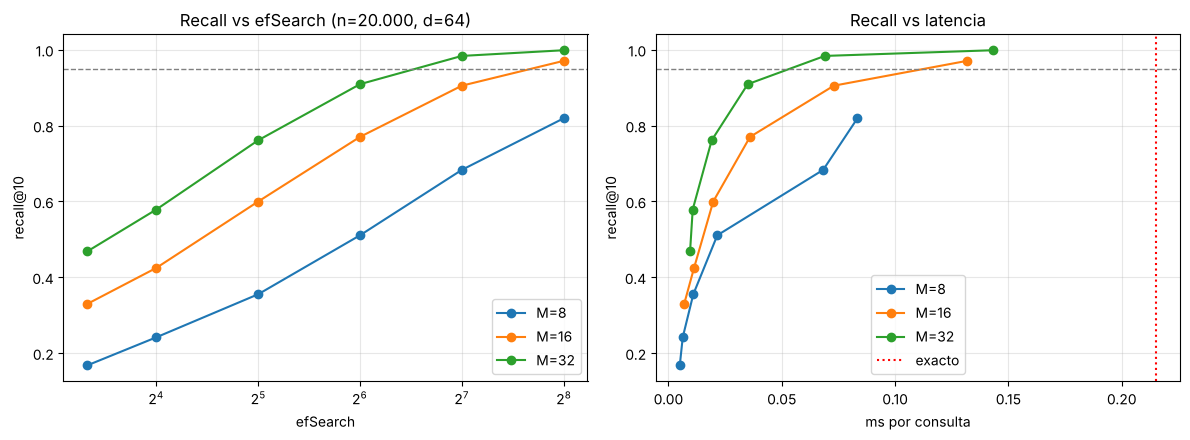

efSearch mínimo con M=16 para recall ≥ 0.95: 256


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for M in (8, 16, 32):
    sub = [r for r in rows if r[0] == M]
    axes[0].plot([r[1] for r in sub], [r[2] for r in sub], marker="o", label=f"M={M}")
    axes[1].plot([r[3] for r in sub], [r[2] for r in sub], marker="o", label=f"M={M}")
for ax in axes:
    ax.axhline(0.95, color="gray", ls="--", lw=1)
    ax.set_ylabel("recall@10"); ax.grid(alpha=.3); ax.legend()
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("efSearch"); axes[0].set_title("Recall vs efSearch (n=20.000, d=64)")
axes[1].axvline(t_flat, color="red", ls=":", lw=1.5, label="exacto")
axes[1].set_xlabel("ms por consulta"); axes[1].set_title("Recall vs latencia"); axes[1].legend()
plt.tight_layout(); plt.show()

ok16 = [r for r in rows if r[0] == 16 and r[2] >= 0.95]
print("efSearch mínimo con M=16 para recall ≥ 0.95:", ok16[0][1] if ok16 else "ninguno de la grilla")

### Barrido de `n`: ¿desde qué tamaño HNSW gana al exacto?

Con `M=16`, `efConstruction=100`, para cada `n` busco el menor `efSearch` (grilla ampliada hasta 2048) que da recall ≥ 0.95 y comparo su latencia con la búsqueda exacta. También mido la latencia **consulta por consulta** (lote de 1), que es como llega una pregunta a un RAG; en lote de 200 la búsqueda exacta se convierte en una multiplicación de matrices muy optimizada (BLAS).

In [4]:
def per_query_ms(index, queries, k=10):
    t0 = time.time()
    for q in queries:
        index.search(q[None, :], k)
    return (time.time() - t0) / len(queries) * 1000

EFS_SWEEP = (16, 32, 64, 128, 256, 512, 1024, 2048)   # grilla ampliada: con n grande 256 no alcanza
sweep = []
for n_i in (20_000, 100_000, 500_000):
    xb_i = rng.random((n_i, d), dtype="float32")
    fl = faiss.IndexFlatL2(d); fl.add(xb_i)
    t0 = time.time(); _, It = fl.search(xq, k); flat_batch = (time.time() - t0) / nq * 1000
    flat_single = per_query_ms(fl, xq[:50])
    hn = faiss.IndexHNSWFlat(d, 16); hn.hnsw.efConstruction = 100
    t0 = time.time(); hn.add(xb_i); build = time.time() - t0
    chosen = None
    for ef in EFS_SWEEP:
        hn.hnsw.efSearch = ef
        t0 = time.time(); _, I = hn.search(xq, k); ms_b = (time.time() - t0) / nq * 1000
        rec = recall_at_k(I, It)
        if rec >= 0.95:
            chosen = (ef, rec, ms_b, per_query_ms(hn, xq[:50])); break
    if chosen is None:
        chosen = (ef, rec, ms_b, per_query_ms(hn, xq[:50]))
    sweep.append((n_i, flat_batch, flat_single, build, *chosen))
    print(f"n={n_i:,} listo")

print("\n| n | exacto ms/q (lote) | exacto ms/q (1 a 1) | HNSW build (s) | efSearch p/ recall≥0.95 | recall | HNSW ms/q (lote) | HNSW ms/q (1 a 1) | speedup 1 a 1 |")
print("|---:|---:|---:|---:|---:|---:|---:|---:|---:|")
for n_i, fb, fs, b, ef, rec, hb, hs in sweep:
    print(f"| {n_i:,} | {fb:.3f} | {fs:.3f} | {b:.1f} | {ef} | {rec:.3f} | {hb:.3f} | {hs:.3f} | {fs / hs:.1f}× |")

n=20,000 listo


n=100,000 listo


n=500,000 listo

| n | exacto ms/q (lote) | exacto ms/q (1 a 1) | HNSW build (s) | efSearch p/ recall≥0.95 | recall | HNSW ms/q (lote) | HNSW ms/q (1 a 1) | speedup 1 a 1 |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 20,000 | 0.122 | 0.462 | 1.1 | 256 | 0.972 | 0.109 | 0.220 | 2.1× |
| 100,000 | 0.573 | 1.996 | 7.3 | 1024 | 0.974 | 0.654 | 1.358 | 1.5× |
| 500,000 | 2.730 | 9.127 | 47.8 | 2048 | 0.939 | 2.357 | 4.841 | 1.9× |


### Datos aleatorios vs embeddings reales

Los vectores uniformes en 64 dimensiones son un caso difícil: no tienen estructura de clusters y, por la concentración de distancias, el vecino 10 está casi tan lejos como el 100. El grafo no tiene «barrios» claros que explotar y hace falta un `efSearch` alto. Los embeddings de texto viven cerca de una variedad de baja dimensión intrínseca y forman clusters por tema, así que se espera más recall con el mismo `efSearch`. El análisis completo está en `RESPUESTAS.md`.

---
## Preparación (C4, C5, C6): papers, embeddings y `build_store`

Reconstruye lo mínimo del notebook 03: descarga los dos PDFs (con respaldo en el repo del curso), los convierte con MarkItDown y define `build_store`.

In [ ]:
%pip install -qU "markitdown[pdf]" langchain langchain-core langchain-text-splitters langchain-nvidia-ai-endpoints langchain-qdrant qdrant-client requests

In [ ]:
import os, getpass, re, time, csv, io
from pathlib import Path
import requests
from markitdown import MarkItDown
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_nvidia_ai_endpoints import NVIDIAEmbeddings
from qdrant_client import QdrantClient, models
from qdrant_client.models import Distance, VectorParams
from langchain_qdrant import QdrantVectorStore

try:
    from google.colab import userdata
    NVIDIA_API_KEY = userdata.get("NVIDIA_API_KEY")
except (ImportError, KeyError):
    NVIDIA_API_KEY = os.getenv("NVIDIA_API_KEY")
if not NVIDIA_API_KEY:
    NVIDIA_API_KEY = getpass.getpass("NVIDIA_API_KEY: ").strip()
os.environ["NVIDIA_API_KEY"] = NVIDIA_API_KEY

EMBEDDING_MODEL = "nvidia/nemotron-3-embed-1b"
embeddings = NVIDIAEmbeddings(model=EMBEDDING_MODEL, truncate="END")
EMBEDDING_DIM = len(embeddings.embed_query("dimension probe"))

def with_retry(fn, *args, tries=6, wait=20, **kwargs):
    for attempt in range(1, tries + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as error:
            if any(s in str(error) for s in ("429", "Too Many", "rate limit")) and attempt < tries:
                print(f"⏳ Rate limit; reintento en {wait}s"); time.sleep(wait); continue
            raise

DOCS_DIR = Path("papers"); DOCS_DIR.mkdir(exist_ok=True)
PAPERS = {"attention_paper.pdf": "https://arxiv.org/pdf/1706.03762",
          "rag_paper.pdf": "https://arxiv.org/pdf/2005.11401"}
BACKUP = "https://raw.githubusercontent.com/EAFIT-IA/si3003-artificial-intelligence/main/notebooks/lecture10/papers/"
for name, url in PAPERS.items():
    dest = DOCS_DIR / name
    if dest.exists() and dest.stat().st_size > 10_000:
        continue
    for u in (url, BACKUP + name):
        try:
            r = requests.get(u, timeout=90); r.raise_for_status()
            if r.content.startswith(b"%PDF"):
                dest.write_bytes(r.content); print("⬇", name, "desde", u); break
        except Exception as e:
            print("⚠️", u, e)

md = MarkItDown(enable_plugins=False)
attention_text = md.convert(str(DOCS_DIR / "attention_paper.pdf")).text_content
rag_text = md.convert(str(DOCS_DIR / "rag_paper.pdf")).text_content
CORPUS = [(attention_text, "Attention Is All You Need", "attention_paper.pdf"),
          (rag_text, "Retrieval-Augmented Generation", "rag_paper.pdf")]

def make_docs(chunk_size, chunk_overlap):
    sp = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=chunk_overlap,
                                        separators=["\n\n", "\n", ".", " "])
    return [Document(page_content=c, metadata={"title": t, "source": s, "chunk_index": i})
            for text, t, s in CORPUS for i, c in enumerate(sp.split_text(text)) if len(c.strip()) >= 30]

def build_store(chunk_size, chunk_overlap, client=None, name=None):
    docs = make_docs(chunk_size, chunk_overlap)
    name = name or f"exp_{chunk_size}_{chunk_overlap}"
    client = client or QdrantClient(":memory:")
    client.create_collection(collection_name=name,
                             vectors_config=VectorParams(size=EMBEDDING_DIM, distance=Distance.COSINE))
    store = QdrantVectorStore(client=client, collection_name=name, embedding=embeddings)
    with_retry(store.add_documents, docs)
    return store, len(docs)

print(f"✅ Listo: {len(attention_text):,} + {len(rag_text):,} caracteres | dim={EMBEDDING_DIM}")

## C4 · Evaluación automática de la recuperación

`eval/preguntas.csv` tiene 10 preguntas con `fuente_esperada` y una `palabra_clave` que debe aparecer en el chunk correcto. Elegí palabras clave **robustas al texto que produce MarkItDown**, que pega muchas palabras sin espacios (p. ej. «WeusedtheAdamoptimizer»): por eso uso «0.98», «P100», «21M», «dotproducts» y no frases como «8 attention heads». Verifiqué que cada palabra clave aparece en al menos un chunk de la fuente esperada con los tres `chunk_size`.

La recuperación se hace **sin umbral** (similitud pura con `k`), para medir solo el ranking.

In [ ]:
CSV_PATH = Path("eval/preguntas.csv")
if not CSV_PATH.exists():
    CSV_PATH.parent.mkdir(exist_ok=True)
    CSV_PATH.write_text(requests.get(
        "https://raw.githubusercontent.com/dguemo/si3003-workshop-rag-dguemo/main/eval/preguntas.csv", timeout=30).text,
        encoding="utf-8")

def cargar_preguntas(ruta=CSV_PATH):
    with open(ruta, encoding="utf-8") as f:
        return list(csv.DictReader(f))

def hit_at_k(retriever, filas):
    hits = 0
    for r in filas:
        docs = retriever.invoke(r["pregunta"])
        ok = any(r["palabra_clave"].lower() in d.page_content.lower()
                 and d.metadata["source"] == r["fuente_esperada"] for d in docs)
        hits += ok
    return hits / len(filas)

filas = cargar_preguntas()
# Control: la palabra clave existe en algún chunk de la fuente esperada
for cs, ov in [(400, 52), (900, 120), (1500, 195)]:
    docs = make_docs(cs, ov)
    missing = [r["id"] for r in filas if not any(r["palabra_clave"].lower() in d.page_content.lower()
               and d.metadata["source"] == r["fuente_esperada"] for d in docs)]
    print(f"chunk_size={cs}: palabras clave sin chunk → {missing or 'ninguna'}")

STORES = {}
print("\n| chunk_size | # chunks | hit@3 | hit@5 |\n|---:|---:|---:|---:|")
for cs, ov in [(400, 52), (900, 120), (1500, 195)]:
    store, n = build_store(cs, ov)
    STORES[cs] = store
    h3 = hit_at_k(store.as_retriever(search_kwargs={"k": 3}), filas)
    h5 = hit_at_k(store.as_retriever(search_kwargs={"k": 5}), filas)
    print(f"| {cs} | {n} | {h3:.0%} | {h5:.0%} |")

In [ ]:
# Detalle por pregunta (chunk_size=900, k=5): ¿en qué posición aparece el chunk correcto?
store = STORES[900]
print("| id | pregunta | fuente esperada | posición del primer acierto (k=5) |\n|---|---|---|---|")
for r in filas:
    docs = store.as_retriever(search_kwargs={"k": 5}).invoke(r["pregunta"])
    pos = next((i + 1 for i, d in enumerate(docs) if r["palabra_clave"].lower() in d.page_content.lower()
                and d.metadata["source"] == r["fuente_esperada"]), "—")
    print(f"| {r['id']} | {r['pregunta']} | {r['fuente_esperada']} | {pos} |")

## C5 · MMR frente a similitud pura

Mismo índice (`chunk_size=900`). Mido **redundancia** como el coseno medio entre pares de los 5 chunks recuperados (más alto = más repetidos) y **cobertura** como cuántos chunks distintos de cada paper aparecen y qué tan dispersos están (`chunk_index`).

In [ ]:
import itertools
import numpy as np

C5_QUESTIONS = [
    "What is multi-head attention?",
    "Which datasets and tasks were used to evaluate RAG?",
    "How does RAG compare to BART on Jeopardy question generation?",
]
store = STORES[900]
sim_r = store.as_retriever(search_type="similarity", search_kwargs={"k": 5})
mmr_r = store.as_retriever(search_type="mmr", search_kwargs={"k": 5, "fetch_k": 20, "lambda_mult": 0.5})

def redundancy(docs):
    vecs = np.array(with_retry(embeddings.embed_documents, [d.page_content for d in docs]))
    vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)
    pairs = list(itertools.combinations(range(len(docs)), 2))
    return float(np.mean([vecs[i] @ vecs[j] for i, j in pairs])) if pairs else float("nan")

def describe(docs):
    return ", ".join(f"{d.metadata['source'].split('_')[0]}#{d.metadata['chunk_index']}" for d in docs)

print("| Pregunta | Estrategia | Chunks (paper#chunk) | Redundancia (coseno medio entre pares) |\n|---|---|---|---:|")
C5 = {}
for q in C5_QUESTIONS:
    for name, r in (("similitud", sim_r), ("MMR λ=0.5", mmr_r)):
        docs = r.invoke(q); C5[(q, name)] = docs
        print(f"| {q} | {name} | {describe(docs)} | {redundancy(docs):.3f} |")

In [ ]:
# Lado a lado: primeros 150 caracteres de cada chunk para la pregunta 1
q = C5_QUESTIONS[0]
for name in ("similitud", "MMR λ=0.5"):
    print(f"\n=== {name} ===")
    for d in C5[(q, name)]:
        print(f"- [{d.metadata['source']} #{d.metadata['chunk_index']}] {d.page_content[:150].replace(chr(10), ' ')}…")

## C6 · Persistencia del índice en disco

1. Ejecuta la Preparación y esta celda: como la colección no existe, **indexa** y mide el tiempo.
2. *Entorno de ejecución → Reiniciar sesión*. Vuelve a ejecutar **solo** la celda de imports/credenciales de la Preparación (no la descarga ni la conversión) y luego esta celda: ahora **reabre** sin reindexar y responde.

> El disco de Colab se borra al terminar la sesión; para que sobreviva de verdad, cambia `QDRANT_PATH` a una carpeta de Google Drive montada.

In [ ]:
QDRANT_PATH = "./qdrant_data"      # p. ej. "/content/drive/MyDrive/qdrant_data" con Drive montado
PERSIST_COLLECTION = "academic_papers_persist"

try:
    persist_client
except NameError:
    persist_client = QdrantClient(path=QDRANT_PATH)   # el modo local bloquea la carpeta: un cliente por sesión

t0 = time.time()
if persist_client.collection_exists(PERSIST_COLLECTION):
    pstore = QdrantVectorStore(client=persist_client, collection_name=PERSIST_COLLECTION, embedding=embeddings)
    action = "reabrir (sin reindexar)"
else:
    pstore, _ = build_store(900, 120, client=persist_client, name=PERSIST_COLLECTION)
    action = "indexar desde cero"
elapsed = time.time() - t0

n_points = persist_client.count(PERSIST_COLLECTION).count
hit = pstore.similarity_search_with_score("What BLEU score did the big Transformer achieve on WMT 2014 English-to-German?", k=1)[0]
print(f"| Acción | Tiempo (s) | Puntos en la colección | Top-1 de prueba |\n|---|---:|---:|---|")
print(f"| {action} | {elapsed:.2f} | {n_points} | {hit[0].metadata['source']}#{hit[0].metadata['chunk_index']} ({hit[1]:.3f}) |")